# RSI Mean Reversion Strategy — LQD

**IEOR 4571 | Team 6 | Dionissios Kakissis**

This notebook backtests an RSI mean reversion strategy for LQD and compares it with buy and hold. It uses the same adjusted LQD prices and $100 starting portfolio as Raj's moving average notebook.

**Rules:** Calculate the 14 day Wilder RSI. Go long below 30, short above 70, and close the position when RSI returns to 50. Positions are applied from the next trading day, since we only know the day's RSI after the close.

I also report results before and after assumed trading costs. The cost assumption is illustrative, and the backtest does not model financing costs for short positions.

The historical price download is saved as a CSV so the same data can be reused later.


In [2]:
%pip install -q yfinance

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({'figure.figsize': (11, 5), 'axes.grid': True})

In [4]:
# Use the same LQD history as the moving-average notebook.
SYMBOL = 'LQD'
START_DATE = '2002-12-31'
END_DATE_EXCLUSIVE = '2026-11-19'  # Nov 18, 2026 is the last possible included day.
TEST_START = '2020-01-01'  # Keep 2020 onward for testing.

RSI_WINDOW = 14
OVERSOLD = 30
OVERBOUGHT = 70
EXIT_LEVEL = 50
COST_BPS = 5.0  # Assumed cost per unit of turnover; report gross too.
TRADING_DAYS_PER_YEAR = 252
INITIAL_VALUE = 100.0

DATA_DIR = Path('data')
OUTPUT_DIR = Path('outputs')
DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
PRICE_CSV = DATA_DIR / 'LQD_adjusted_close.csv'

In [5]:
def load_adjusted_close(csv_path=PRICE_CSV):
    """Read cached data, or fetch adjusted LQD closes and save a reproducible CSV."""
    if Path(csv_path).exists():
        raw = pd.read_csv(csv_path)
        expected = {'Date', 'AdjClose'}
        if not expected.issubset(raw.columns):
            raise ValueError(f'{csv_path} must contain columns {sorted(expected)}')
        close = pd.Series(raw['AdjClose'].to_numpy(dtype=float),
                          index=pd.to_datetime(raw['Date']), name=SYMBOL)
        source = f'cached adjusted-price CSV: {csv_path}'
    else:
        try:
            import yfinance as yf
        except ImportError as exc:
            raise ImportError('Install required packages: pip install -r requirements.txt') from exc
        hist = yf.download(SYMBOL, start=START_DATE, end=END_DATE_EXCLUSIVE,
                           auto_adjust=True, progress=False)
        if hist.empty:
            raise RuntimeError('No LQD data returned. Check the connection or provide data/LQD_adjusted_close.csv.')
        close = hist['Close']
        if isinstance(close, pd.DataFrame):  # yfinance may return MultiIndex columns
            close = close[SYMBOL] if SYMBOL in close.columns else close.iloc[:, 0]
        close = close.rename(SYMBOL)
        source = 'Yahoo Finance via yfinance (auto_adjust=True)'

    close = pd.Series(close, dtype=float)
    close.index = pd.to_datetime(close.index).tz_localize(None)
    close = close.loc[(close.index >= pd.Timestamp(START_DATE)) &
                      (close.index < pd.Timestamp(END_DATE_EXCLUSIVE))].sort_index()
    close = close[~close.index.duplicated(keep='last')].dropna()
    if len(close) < 300 or (close <= 0).any() or not np.isfinite(close.to_numpy()).all():
        raise ValueError('Insufficient / invalid adjusted closing-price history.')
    close.rename('AdjClose').rename_axis('Date').to_csv(csv_path)
    return close.rename(SYMBOL), source

prices, data_source = load_adjusted_close()
print(f'Data source: {data_source}')
print(f'{len(prices):,} sessions: {prices.index[0].date()} to {prices.index[-1].date()}')
display(prices.head().to_frame('Adjusted LQD close'))

Data source: Yahoo Finance via yfinance (auto_adjust=True)
6,010 sessions: 2002-12-31 to 2026-11-18


,Adjusted LQD close
Date,
2002-12-31,39.961372
2003-01-02,39.101597
2003-01-03,39.323830
2003-01-06,39.305599
2003-01-07,39.455009


## 1. RSI and trading rules

I use Wilder's RSI calculation with a 14 day lookback. The first few observations are used to initialize the indicator, so the strategy starts with no position.

Positions are +1 for long, negative one for short, and 0 for cash. I use the 50 level to close trades instead of switching positions immediately between long and short. The signal is shifted by one day when calculating returns to avoid using today's closing price to trade today's return.


In [6]:
def rsi_wilder(close: pd.Series, window: int = 14) -> pd.Series:
    """Wilder RSI, including the initial simple-average seed and zero-loss edge cases."""
    if window < 2:
        raise ValueError('RSI window must be at least 2.')
    s = pd.Series(close, dtype=float)
    n = len(s)
    gains = s.diff().clip(lower=0).to_numpy()
    losses = (-s.diff()).clip(lower=0).to_numpy()
    out = np.full(n, np.nan)
    if n <= window:
        return pd.Series(out, index=s.index, name='rsi')
    ag = gains[1:window + 1].mean()
    al = losses[1:window + 1].mean()
    for i in range(window, n):
        if i > window:
            ag = (ag * (window - 1) + gains[i]) / window
            al = (al * (window - 1) + losses[i]) / window
        if ag == 0 and al == 0:
            out[i] = 50.0
        elif al == 0:
            out[i] = 100.0
        elif ag == 0:
            out[i] = 0.0
        else:
            out[i] = 100.0 - 100.0 / (1 + ag / al)
    return pd.Series(out, index=s.index, name='rsi')


def rsi_positions(rsi: pd.Series, lower=30, upper=70, exit_level=50) -> pd.Series:
    """End-of-day target holdings: +1, -1, or 0; maintain until midpoint exit."""
    if not (0 < lower < exit_level < upper < 100):
        raise ValueError('Require 0 < lower < exit_level < upper < 100.')
    positions = np.zeros(len(rsi), dtype=int)
    previous = 0
    for i, value in enumerate(rsi.to_numpy()):
        if np.isnan(value):
            previous = 0
        elif previous == 0:
            if value < lower:
                previous = 1
            elif value > upper:
                previous = -1
        elif previous == 1 and value >= exit_level:
            previous = 0
        elif previous == -1 and value <= exit_level:
            previous = 0
        positions[i] = previous
    return pd.Series(positions, index=rsi.index, name='signal')

In [7]:
def backtest_rsi(close: pd.Series, window=14, lower=30, upper=70,
                 exit_level=50, cost_bps=5.0) -> pd.DataFrame:
    """Daily close-to-close RSI backtest, trading next session after each signal."""
    if cost_bps < 0:
        raise ValueError('Trading cost cannot be negative.')
    asset = pd.Series(close, dtype=float).rename('adj_close')
    rsi = rsi_wilder(asset, window=window)
    target = rsi_positions(rsi, lower=lower, upper=upper, exit_level=exit_level)
    held = target.shift(1).fillna(0).astype(int)  # NO same-day signal/return leakage
    asset_return = asset.pct_change(fill_method=None).fillna(0.0)
    turnover = held.diff().abs().fillna(held.abs())
    cost = (cost_bps / 10_000.0) * turnover
    gross_return = held * asset_return
    net_return = gross_return - cost
    benchmark_return = asset_return.copy()
    df = pd.DataFrame({
        'adj_close': asset, 'rsi': rsi, 'signal': target, 'held_position': held,
        'asset_return': asset_return, 'turnover': turnover, 'cost': cost,
        'gross_return': gross_return, 'net_return': net_return,
        'benchmark_return': benchmark_return,
    })
    for rcol, ecol in [('gross_return', 'equity_gross'),
                       ('net_return', 'equity_net'),
                       ('benchmark_return', 'equity_buy_hold')]:
        if (df[rcol] <= -1).any():
            raise ValueError('Portfolio lost 100% or more in one session; inspect returns.')
        df[ecol] = INITIAL_VALUE * (1.0 + df[rcol]).cumprod()
    return df


def performance_statistics(returns: pd.Series) -> dict:
    """Compute risk/return metrics from ALL trading days, including zero-return days."""
    r = pd.Series(returns, dtype=float).dropna()
    if r.empty:
        raise ValueError('At least one return is needed.')
    equity_multiple = (1.0 + r).cumprod()
    annual_mean = r.mean() * TRADING_DAYS_PER_YEAR
    annual_vol = r.std(ddof=1) * np.sqrt(TRADING_DAYS_PER_YEAR) if len(r) > 1 else np.nan
    peak = equity_multiple.cummax().clip(lower=1.0)
    drawdown = equity_multiple / peak - 1.0
    return {
        'Trading Days': len(r),
        'Mean Daily Return': r.mean(),
        'Daily Return Std': r.std(ddof=1),
        'Annualized Mean Return': annual_mean,
        'Annualized Volatility': annual_vol,
        'CAGR': equity_multiple.iloc[-1] ** (TRADING_DAYS_PER_YEAR / len(r)) - 1,
        'Cumulative Return': equity_multiple.iloc[-1] - 1,
        'Max Drawdown': drawdown.min(),
        'Sharpe (rf=0)': annual_mean / annual_vol if annual_vol > 0 else np.nan,
    }


def compare_period(df: pd.DataFrame, start=None, end=None) -> pd.DataFrame:
    """Returns and consistent metrics over the same dates for all approaches."""
    segment = df.loc[start:end]
    cols = {'RSI gross': 'gross_return', 'RSI net': 'net_return',
            'Buy & hold': 'benchmark_return'}
    return pd.DataFrame({name: performance_statistics(segment[col])
                         for name, col in cols.items()}).T.rename_axis('Strategy')

## 2. Baseline backtest

First I test the standard 14 day RSI with 30/70 entry thresholds and an exit at 50. I show both gross returns and returns after an assumed cost of 5 basis points per unit of turnover. These are example trading costs, not estimated LQD transaction costs.


In [8]:
base = backtest_rsi(prices, window=RSI_WINDOW, lower=OVERSOLD,
                    upper=OVERBOUGHT, exit_level=EXIT_LEVEL, cost_bps=COST_BPS)
train = base.loc[base.index < pd.Timestamp(TEST_START)]
test = base.loc[base.index >= pd.Timestamp(TEST_START)]
if min(len(train), len(test)) < 250:
    raise ValueError('Train/test split too small. Check data and TEST_START.')

print('Baseline full-period results (decimal returns, e.g. 0.05 = 5%):')
display(compare_period(base).round(4))
print('Out-of-sample baseline results:')
display(compare_period(base, start=TEST_START).round(4))

Baseline full-period results (decimal returns, e.g. 0.05 = 5%):


,Trading Days,Mean Daily Return,Daily Return Std,Annualized Mean Return,Annualized Volatility,CAGR,Cumulative Return,Max Drawdown,Sharpe (rf=0)
Strategy,,,,,,,,,
RSI gross,6010.0,-0.0001,0.0039,-0.0137,0.0620,-0.0155,-0.3109,-0.4004,-0.2210
RSI net,6010.0,-0.0001,0.0039,-0.0170,0.0620,-0.0187,-0.3626,-0.4325,-0.2737
Buy & hold,6010.0,0.0002,0.0052,0.0432,0.0833,0.0406,1.5812,-0.2495,0.5189


Out-of-sample baseline results:


,Trading Days,Mean Daily Return,Daily Return Std,Annualized Mean Return,Annualized Volatility,CAGR,Cumulative Return,Max Drawdown,Sharpe (rf=0)
Strategy,,,,,,,,,
RSI gross,1730.0,-0.0,0.0047,-0.0051,0.0740,-0.0078,-0.0524,-0.1645,-0.0691
RSI net,1730.0,-0.0,0.0047,-0.0085,0.0740,-0.0111,-0.0739,-0.1658,-0.1143
Buy & hold,1730.0,0.0,0.0063,0.0102,0.1006,0.0052,0.0361,-0.2495,0.1016


## 3. Parameter comparison

I also compare RSI windows of 7, 14, and 21 days and entry thresholds of 25, 30, and 35 (with matching upper thresholds). This is similar to the parameter search in Raj's notebook.

I choose the parameters using only the data before 2020, then evaluate that choice on 2020–2026 data. The standard 14/30/70 version stays as the baseline. The tuned version is just an extra comparison; good test results don't guarantee the same performance in the future.


In [9]:
records = []
for window in (7, 14, 21):
    for entry in (25, 30, 35):
        trial = backtest_rsi(prices, window=window, lower=entry,
                             upper=100-entry, exit_level=50, cost_bps=COST_BPS)
        train_returns = trial.loc[trial.index < pd.Timestamp(TEST_START), 'net_return']
        stats = performance_statistics(train_returns)
        records.append({'RSI Window': window, 'Entry Threshold': entry,
                        'Train Sharpe (rf=0)': stats['Sharpe (rf=0)'],
                        'Train CAGR': stats['CAGR'],
                        'Train Max Drawdown': stats['Max Drawdown']})

search_results = pd.DataFrame(records).sort_values('Train Sharpe (rf=0)', ascending=False)
if search_results['Train Sharpe (rf=0)'].notna().sum() == 0:
    raise RuntimeError('Parameter grid produced no defined Sharpe ratio.')
best = search_results.dropna(subset=['Train Sharpe (rf=0)']).iloc[0]
best_window, best_entry = int(best['RSI Window']), int(best['Entry Threshold'])
tuned = backtest_rsi(prices, window=best_window, lower=best_entry,
                     upper=100-best_entry, exit_level=50, cost_bps=COST_BPS)

print(f'Train-only selection: RSI={best_window}; entry at {best_entry}/{100-best_entry}; exit at 50')
display(search_results.round(4))
print('Tuned RSI test results (an additional sensitivity check):')
display(compare_period(tuned, start=TEST_START).round(4))

Train-only selection: RSI=21; entry at 30/70; exit at 50


,RSI Window,Entry Threshold,Train Sharpe (rf=0),Train CAGR,Train Max Drawdown
7,21,30,-0.0628,-0.0047,-0.1683
6,21,25,-0.1067,-0.0061,-0.1287
3,14,25,-0.1530,-0.0092,-0.2031
8,21,35,-0.2924,-0.0191,-0.2964
4,14,30,-0.3616,-0.0218,-0.3333
0,7,25,-0.4407,-0.0276,-0.4074
5,14,35,-0.4620,-0.0296,-0.4340
1,7,30,-0.5912,-0.0384,-0.5057
2,7,35,-0.6300,-0.0430,-0.5455


Tuned RSI test results (an additional sensitivity check):


,Trading Days,Mean Daily Return,Daily Return Std,Annualized Mean Return,Annualized Volatility,CAGR,Cumulative Return,Max Drawdown,Sharpe (rf=0)
Strategy,,,,,,,,,
RSI gross,1730.0,0.0001,0.0042,0.0157,0.0670,0.0136,0.0969,-0.1463,0.2344
RSI net,1730.0,0.0001,0.0042,0.0142,0.0669,0.0121,0.0860,-0.1463,0.2127
Buy & hold,1730.0,0.0000,0.0063,0.0102,0.1006,0.0052,0.0361,-0.2495,0.1016


## 4. Charts and performance comparison

The charts compare LQD prices, RSI, strategy returns, and drawdowns. The test period portfolio curves all start at $100 and cover the same dates. Returns use the position held from the previous day's signal.


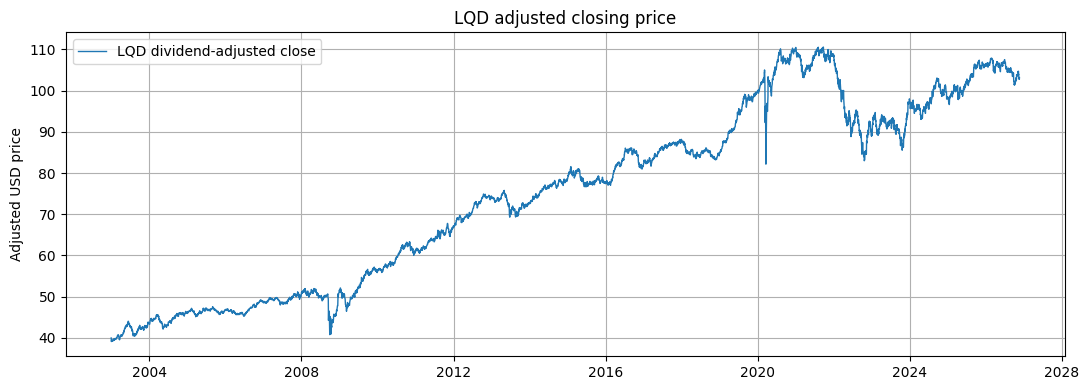

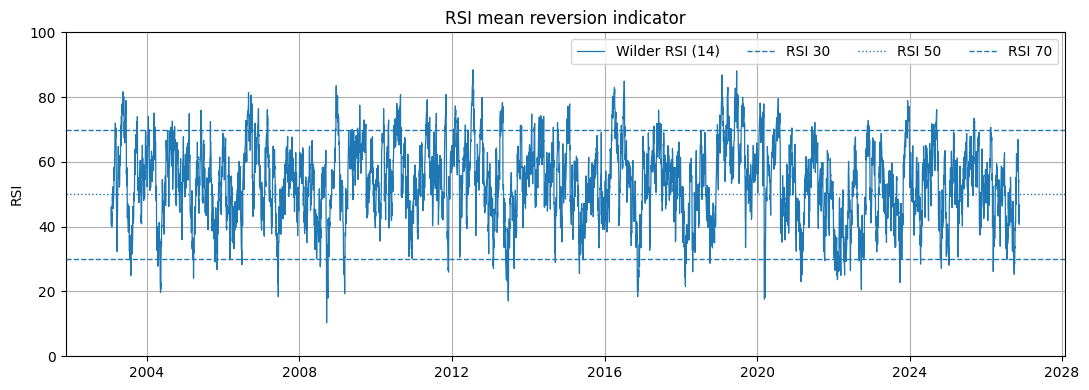

In [10]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(prices.index, prices, linewidth=1, label='LQD dividend-adjusted close')
ax.set(title='LQD adjusted closing price', ylabel='Adjusted USD price')
ax.legend()
fig.tight_layout(); fig.savefig(OUTPUT_DIR/'lqd_adjusted_price.png', dpi=170)
plt.show()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(base.index, base['rsi'], linewidth=0.9, label='Wilder RSI (14)')
for y, style in [(30, '--'), (50, ':'), (70, '--')]:
    ax.axhline(y, linestyle=style, linewidth=1, label=f'RSI {y}')
ax.set(title='RSI mean reversion indicator', ylabel='RSI', ylim=(0, 100))
ax.legend(ncol=4)
fig.tight_layout(); fig.savefig(OUTPUT_DIR/'rsi_indicator.png', dpi=170)
plt.show()

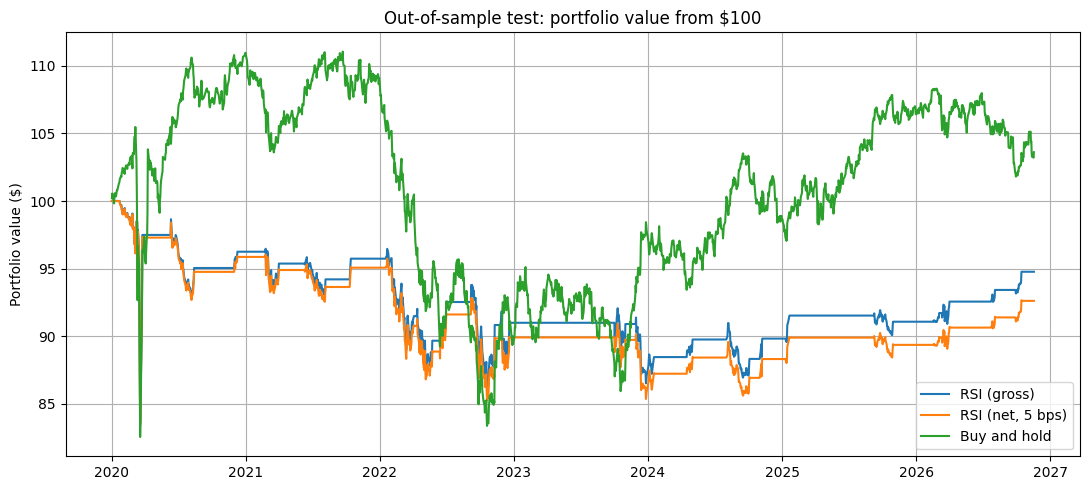

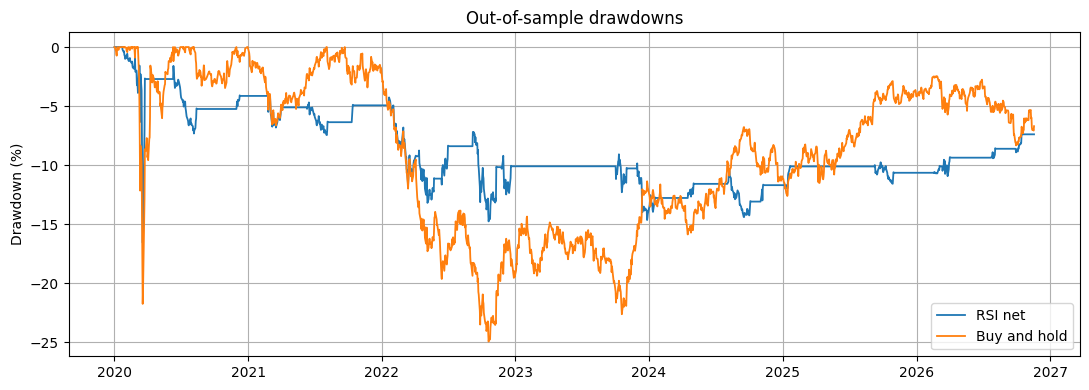

In [11]:
view = base.loc[TEST_START:].copy()
fig, ax = plt.subplots(figsize=(11, 5))
for label, name in [('RSI (gross)', 'gross_return'),
                    ('RSI (net, 5 bps)', 'net_return'),
                    ('Buy and hold', 'benchmark_return')]:
    portfolio = INITIAL_VALUE * (1.0 + view[name]).cumprod()
    ax.plot(view.index, portfolio, label=label, linewidth=1.5)
ax.set(title='Out-of-sample test: portfolio value from $100', ylabel='Portfolio value ($)')
ax.legend()
fig.tight_layout(); fig.savefig(OUTPUT_DIR/'rsi_vs_buyhold_test.png', dpi=170)
plt.show()

fig, ax = plt.subplots(figsize=(11, 4))
for label, name in [('RSI net', 'net_return'), ('Buy and hold', 'benchmark_return')]:
    eq = (1 + view[name]).cumprod()
    dd = eq / eq.cummax().clip(lower=1) - 1
    ax.plot(view.index, 100 * dd, label=label, linewidth=1.3)
ax.set(title='Out-of-sample drawdowns', ylabel='Drawdown (%)')
ax.legend()
fig.tight_layout(); fig.savefig(OUTPUT_DIR/'rsi_drawdown_test.png', dpi=170)
plt.show()

## 5. Checks and exported files

I check that the strategy positions are shifted correctly, the RSI stays between 0 and 100, and trading costs are deducted consistently. The final cell saves the data, tables, and figures for the report.


In [12]:
assert (base['held_position'].equals(base['signal'].shift(1).fillna(0).astype(int)))
assert base['rsi'].dropna().between(0, 100).all()
assert (base['turnover'] >= 0).all()
assert np.allclose(base['gross_return'], base['held_position'] * base['asset_return'])
assert np.allclose(base['net_return'], base['gross_return'] - base['cost'])
assert np.isclose(base['benchmark_return'].iloc[0], 0)

# Check that a change to the last price leaves earlier signals alone.
modified_prices = prices.copy()
modified_prices.iloc[-1] *= 1.07
rsi_changed = rsi_wilder(modified_prices, RSI_WINDOW)
assert np.allclose(base['rsi'].iloc[:-1], rsi_changed.iloc[:-1], equal_nan=True)

full_metrics = compare_period(base)
train_metrics = compare_period(base, end=(pd.Timestamp(TEST_START) - pd.Timedelta(days=1)).strftime('%Y-%m-%d'))
test_metrics = compare_period(base, start=TEST_START)
tuned_test_metrics = compare_period(tuned, start=TEST_START)

base.to_csv(OUTPUT_DIR/'rsi_daily_backtest.csv', index_label='Date')
search_results.to_csv(OUTPUT_DIR/'rsi_train_sensitivity.csv', index=False)
full_metrics.to_csv(OUTPUT_DIR/'rsi_full_period_metrics.csv')
train_metrics.to_csv(OUTPUT_DIR/'rsi_train_metrics.csv')
test_metrics.to_csv(OUTPUT_DIR/'rsi_test_metrics.csv')
tuned_test_metrics.to_csv(OUTPUT_DIR/'rsi_tuned_test_metrics.csv')

rsi_net = test_metrics.loc['RSI net']
buy_hold = test_metrics.loc['Buy & hold']
trend = 'outperformed' if rsi_net['Cumulative Return'] > buy_hold['Cumulative Return'] else 'underperformed'
summary = f"""# RSI strategy: measured results (auto-generated)

Data: {SYMBOL}, adjusted close, {prices.index[0].date()} to {prices.index[-1].date()}; source: {data_source}.
Test sample: {test.index[0].date()} to {test.index[-1].date()} ({len(test):,} trading sessions).

Baseline: Wilder RSI({RSI_WINDOW}), entry below {OVERSOLD} / above {OVERBOUGHT}, exit at {EXIT_LEVEL}, held position shifted one trading day.
Costs: illustrative {COST_BPS:g} basis points per one-way 100% notional change (short borrowing and financing excluded).

| Out-of-sample metric | RSI net | Buy and hold |
|---|---:|---:|
| Mean daily return | {rsi_net['Mean Daily Return']:.4%} | {buy_hold['Mean Daily Return']:.4%} |
| Annualized arithmetic mean return | {rsi_net['Annualized Mean Return']:.2%} | {buy_hold['Annualized Mean Return']:.2%} |
| Annualized volatility | {rsi_net['Annualized Volatility']:.2%} | {buy_hold['Annualized Volatility']:.2%} |
| CAGR | {rsi_net['CAGR']:.2%} | {buy_hold['CAGR']:.2%} |
| Cumulative return | {rsi_net['Cumulative Return']:.2%} | {buy_hold['Cumulative Return']:.2%} |
| Maximum drawdown | {rsi_net['Max Drawdown']:.2%} | {buy_hold['Max Drawdown']:.2%} |
| Sharpe, rf=0 | {rsi_net['Sharpe (rf=0)']:.3f} | {buy_hold['Sharpe (rf=0)']:.3f} |

The baseline net RSI strategy **{trend}** buy-and-hold in total compounded returns over this test sample. This retrospective observation does not establish prospective predictive value.

Training-only sensitivity grid tested RSI windows 7, 14, 21 and symmetric entry thresholds 25/75, 30/70, 35/65. The best *training* Sharpe used RSI({best_window}) and entry thresholds {best_entry}/{100-best_entry}; its holdout performance is in `rsi_tuned_test_metrics.csv`. Do not select the preferred strategy by looking at test results.

Limitations: daily-close approximations, illustrative costs, no borrowing/short-locate constraints or cash interest, threshold overfitting risk, and potential nonstationarity in bond ETF behavior. Data include dividends through adjusted prices. Returns are historical and not guarantees.

Figures: `rsi_vs_buyhold_test.png`, `rsi_drawdown_test.png`, `rsi_indicator.png`.
"""
(OUTPUT_DIR/'RSI_results_summary.md').write_text(summary, encoding='utf-8')
print('Checks passed. Files saved in:', OUTPUT_DIR.resolve())
print(summary)

Checks passed. Files saved in: /content/outputs
# RSI strategy: measured results (auto-generated)

Data: LQD, adjusted close, 2002-12-31 to 2026-11-18; source: Yahoo Finance via yfinance (auto_adjust=True).
Test sample: 2020-01-02 to 2026-11-18 (1,730 trading sessions).

Baseline: Wilder RSI(14), entry below 30 / above 70, exit at 50, held position shifted one trading day.
Costs: illustrative 5 basis points per one-way 100% notional change (short borrowing and financing excluded).

| Out-of-sample metric | RSI net | Buy and hold |
|---|---:|---:|
| Mean daily return | -0.0034% | 0.0041% |
| Annualized arithmetic mean return | -0.85% | 1.02% |
| Annualized volatility | 7.40% | 10.06% |
| CAGR | -1.11% | 0.52% |
| Cumulative return | -7.39% | 3.61% |
| Maximum drawdown | -16.58% | -24.95% |
| Sharpe, rf=0 | -0.114 | 0.102 |

The baseline net RSI strategy **underperformed** buy-and-hold in total compounded returns over this test sample. This retrospective observation does not establish pr